In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pandas as pd
from benchmark_func import mean_result, print_summary, run_benchmark, show_graph

from algorithms.baseline import UserBasedCF
from algorithms.implicit_als import ImplicitALS
from utils.data_load import load_dataset, make_subset, save_df, split_train_test_by_time


c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
DATA_PATH = "../data/raw/ratings.csv"

DATA_TRAIN_1M_PATH = "../data/processed/train_1M.csv"
DATA_TEST_1M_PATH = "../data/processed/test_1M.csv"

N_RUNS = 3

In [4]:
df = load_dataset(path=DATA_PATH)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 976.6 MB


In [5]:
df.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [6]:
try:
    train = load_dataset(DATA_TRAIN_1M_PATH)
    test = load_dataset(DATA_TEST_1M_PATH)
except FileNotFoundError:
    subset = make_subset(df=df, n_ratings=1_000_000)
    train, test = split_train_test_by_time(subset)
    save_df(df=train, path=DATA_TRAIN_1M_PATH)
    save_df(df=test, path=DATA_TEST_1M_PATH)

print(train.shape, test.shape)

(800500, 4) (200086, 4)


In [7]:
train.describe()

,userId,movieId,rating,timestamp
count,800500.000000,800500.000000,800500.000000,8.005000e+05
mean,98646.270209,25929.397535,3.572943,1.266412e+09
std,58418.514135,46291.101800,1.062505,2.560993e+08
min,141.000000,1.000000,0.500000,8.243892e+08
25%,47598.000000,1209.000000,3.000000,1.031770e+09
50%,98500.000000,3081.000000,4.000000,1.254978e+09
75%,150270.000000,33166.000000,4.000000,1.498865e+09
max,200935.000000,290263.000000,5.000000,1.696168e+09


In [8]:
test.describe()

,userId,movieId,rating,timestamp
count,200086.00000,200086.000000,200086.000000,2.000860e+05
mean,98647.76692,41712.255165,3.481840,1.306111e+09
std,58423.08884,64574.528694,1.059222,2.653764e+08
min,141.00000,1.000000,0.500000,8.271370e+08
25%,47598.00000,1517.000000,3.000000,1.070599e+09
50%,98484.00000,4487.000000,3.500000,1.335776e+09
75%,150291.00000,65802.000000,4.000000,1.546649e+09
max,200935.00000,292141.000000,5.000000,1.697157e+09


In [9]:
model = UserBasedCF(top_k=20)

results = run_benchmark(model, train, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF: 2.588 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.273 сек.
[timer] Обучение UserBasedCF: 2.543 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.243 сек.
[timer] Обучение UserBasedCF: 2.615 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.270 сек.
UserBasedCF
Количество пользователей: 6,314
Количество объектов: 21,388
Количество оценок в train: 800,500
Разреженность матрицы оценок: 0.5928%
Размер матрицы схожестей: 0.15 ГБ
Среднее train_time 2.5820980866750083
Среднее pred_time 5.261887709299724
Средний recall 0.02803864435793312
Средний ndcg 0.02464104623284104
Количество ненулевых оценок в тестовой матрице: 194,773
Количество релевантных оценок в тестовой матрице (>=3.5): 120,582
Пользователей с ненулевыми оценками в тестовой матрице: 6,313
Пользователей с релевантными оценками в тестовой матрице: 6,215


Подбор гиперпараметров для базовой модели `UserBasedCF`

In [10]:
top_k_values = [5, 10, 15, 20, 30, 50, 100]
results = []

for top_k in top_k_values:
    model = UserBasedCF(top_k=top_k)
    results_top_k = run_benchmark(model, train, test, n_runs=N_RUNS)
    results.append({
        "top_k": top_k,
        "train_time": mean_result(results=results_top_k, param="train_time"),
        "pred_time": mean_result(results=results_top_k, param="pred_time"),
        "recall@10": mean_result(results=results_top_k, param="recall"),
        "ndcg@10": mean_result(results=results_top_k, param="ndcg"),
    })

df = pd.DataFrame(results)

[timer] Обучение UserBasedCF: 2.622 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.595 сек.
[timer] Обучение UserBasedCF: 2.672 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.683 сек.
[timer] Обучение UserBasedCF: 2.665 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.639 сек.
[timer] Обучение UserBasedCF: 2.607 сек.
[timer] Выдача рекомендаций UserBasedCF: 3.567 сек.
[timer] Обучение UserBasedCF: 2.587 сек.
[timer] Выдача рекомендаций UserBasedCF: 3.556 сек.
[timer] Обучение UserBasedCF: 2.530 сек.
[timer] Выдача рекомендаций UserBasedCF: 3.557 сек.
[timer] Обучение UserBasedCF: 2.503 сек.
[timer] Выдача рекомендаций UserBasedCF: 4.438 сек.
[timer] Обучение UserBasedCF: 2.462 сек.
[timer] Выдача рекомендаций UserBasedCF: 4.460 сек.
[timer] Обучение UserBasedCF: 2.450 сек.
[timer] Выдача рекомендаций UserBasedCF: 4.438 сек.
[timer] Обучение UserBasedCF: 2.446 сек.
[timer] Выдача рекомендаций UserBasedCF: 5.401 сек.
[timer] Обучение UserBasedCF: 2.477 сек.
[timer] Выдача рекомендаций U

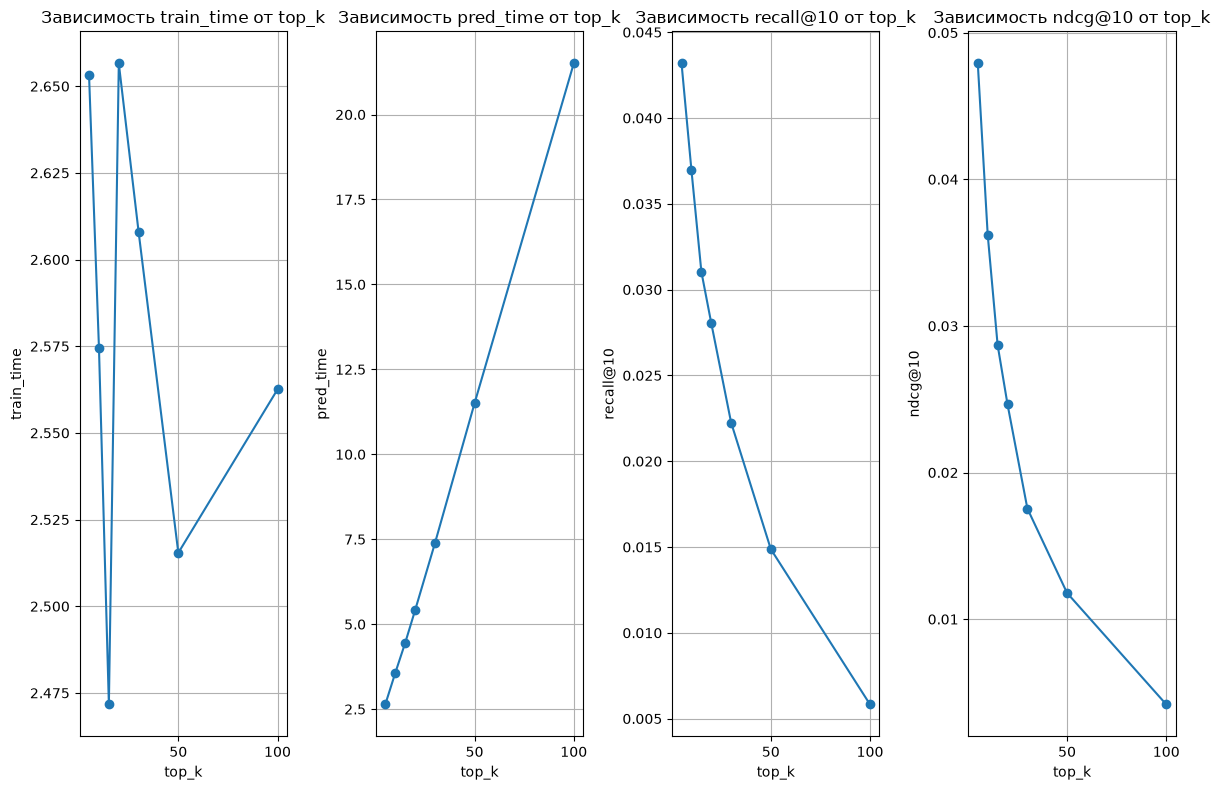

In [ ]:
show_graph(results_df=df, params=["top_k"], metrics=["pred_time", "recall@10", "ndcg@10"], save_dir="graphs/UserBasedCF")

In [13]:
model = UserBasedCF(top_k=5)

results = run_benchmark(model, train, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF: 2.494 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.503 сек.
[timer] Обучение UserBasedCF: 2.525 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.505 сек.
[timer] Обучение UserBasedCF: 2.525 сек.
[timer] Выдача рекомендаций UserBasedCF: 2.498 сек.
UserBasedCF
Количество пользователей: 6,314
Количество объектов: 21,388
Количество оценок в train: 800,500
Разреженность матрицы оценок: 0.5928%
Размер матрицы схожестей: 0.15 ГБ
Среднее train_time 2.514672120412191
Среднее pred_time 2.5020785331726074
Средний recall 0.04318276171931504
Средний ndcg 0.04790683376035909
Количество ненулевых оценок в тестовой матрице: 194,773
Количество релевантных оценок в тестовой матрице (>=3.5): 120,582
Пользователей с ненулевыми оценками в тестовой матрице: 6,313
Пользователей с релевантными оценками в тестовой матрице: 6,215


Таким образом, лучший `top_k=5`:

- при `top_k=5` - самые похожие пользователи, у которых много общих фильмов;
- при `top_k=100` - все, у кого есть хоть 1 общий, включая почти случайных;
- меньше - лучше, потому что сигнал чище.

memory-based CF деградирует при добавлении соседей, потому что нет достаточного числа действительно похожих пользователей.

In [12]:
model = ImplicitALS(factors=64, iterations=20, regularization=0.05, alpha=40.0)

results = run_benchmark(model, train, test, n_runs=N_RUNS)

print_summary(results)

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


[timer] Обучение implicit ALS: 1.106 сек.
[timer] Выдача рекомендаций implicit ALS: 1.024 сек.
[timer] Обучение implicit ALS: 1.128 сек.
[timer] Выдача рекомендаций implicit ALS: 1.090 сек.
[timer] Обучение implicit ALS: 1.033 сек.
[timer] Выдача рекомендаций implicit ALS: 1.005 сек.
Модель: implicit ALS (factors=64, iterations=20, regularization=0.05, alpha=40.0)
Количество пользователей: 6314
Количество объектов: 21388
Количество оценок в train: 800500
Разреженность матрицы взаимодействий: 0.5928%
Среднее train_time 1.0892407894134521
Среднее pred_time 1.0397315820058186
Средний recall 0.02946396294258574
Средний ndcg 0.041783239274723084
